分类变量表: 482 激酶 × 425 变量
One-hot shape: (482, 2113)
Number of all-zero dummy columns: 0
Estimated maximum useful MCA dimensions: 481

Eigenvalue summary, first 20 dimensions:
          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.436        10.97%                     10.97%
1              0.128         3.23%                     14.20%
2              0.094         2.36%                     16.56%
3              0.084         2.12%                     18.68%
4              0.073         1.84%                     20.51%
5              0.063         1.58%                     22.09%
6              0.061         1.54%                     23.63%
7              0.056         1.40%                     25.03%
8              0.049         1.24%                     26.27%
9              0.049         1.24%                     27.51%
10             0.049         1.23%                     28.74%
11             0.046 

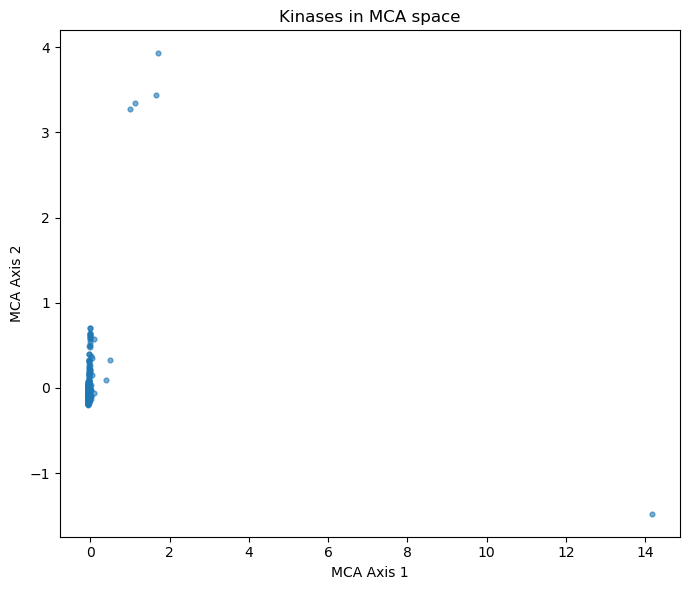

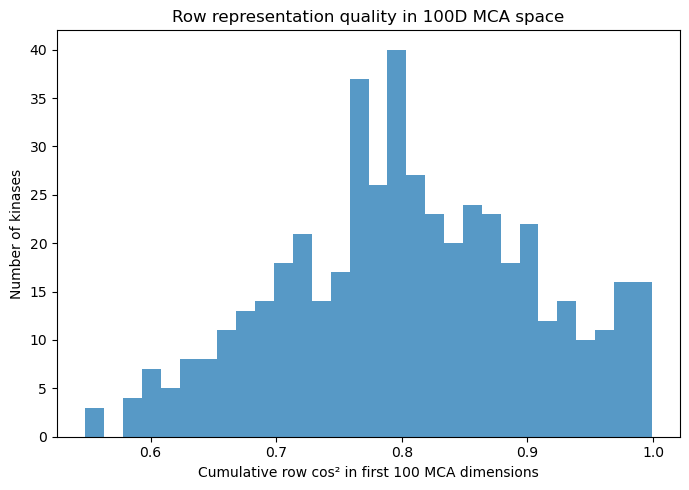

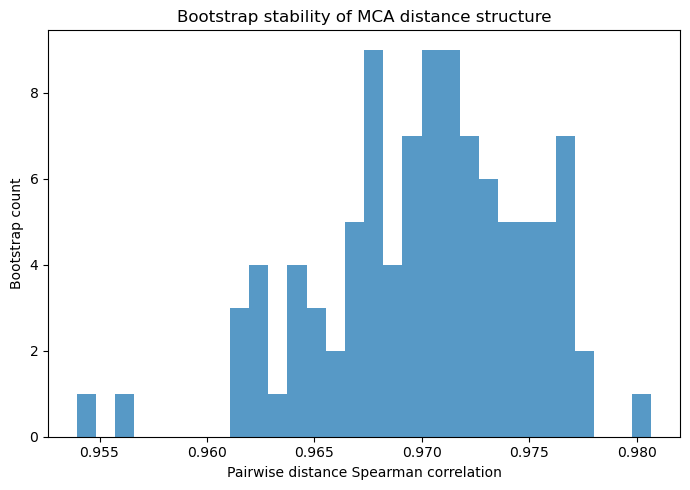

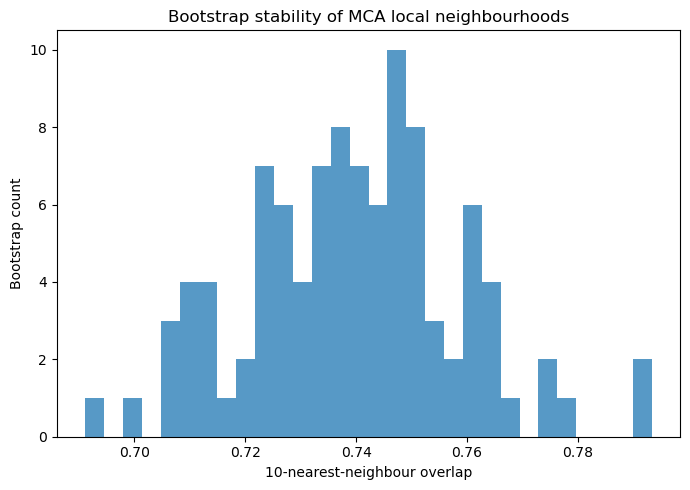

In [13]:
import numpy as np
import pandas as pd
import prince
import matplotlib.pyplot as plt

SYSTEM_SIZES = [8, 3, 4, 3, 5]
SYSTEM_NAMES = ["sidechain", "tertiary", "functional", "secondary", "size"]
SYSTEM_CATEGORIES = [
    ["Aliphatic", "Aromatic", "Sulfur", "Imino", "Amide", "Hydroxyl", "Acidic_sc", "Basic_sc"],
    ["Exposed", "Buried", "Intermediate"],
    ["Acidic_fn", "Basic_fn", "Hydrophobic", "Polar"],
    ["alpha", "beta", "coil"],
    ["Tiny", "Small", "Medium", "Large", "VeryLarge"],
]

N_RESIDUES = 85
BITS_PER_RES = 23

assert sum(SYSTEM_SIZES) == BITS_PER_RES


def onehot_to_categorical(X, strict=True):
    """
    Convert KLIFS 85 x 23 binary physicochemical encoding into
    a categorical table for MCA.

    Input:
        X: array-like, shape [n_samples, 1955]

    Output:
        df_cat: DataFrame, shape [n_samples, 425]
    """
    X = np.asarray(X)
    n = X.shape[0]

    expected_dim = N_RESIDUES * BITS_PER_RES
    if X.shape[1] != expected_dim:
        raise ValueError(
            f"Expected {expected_dim} columns, got {X.shape[1]}. "
            "Please check KLIFS column order and encoding."
        )

    data = {}

    for r in range(N_RESIDUES):
        base = r * BITS_PER_RES
        offset = 0

        for sz, sname, cats in zip(SYSTEM_SIZES, SYSTEM_NAMES, SYSTEM_CATEGORIES):
            block = X[:, base + offset: base + offset + sz]
            row_sums = block.sum(axis=1)

            if strict and np.any(row_sums > 1):
                bad_idx = np.where(row_sums > 1)[0]
                raise ValueError(
                    f"res{r+1:02d}_{sname}: "
                    f"{len(bad_idx)} samples have multiple active categories."
                )

            labels = np.full(n, "Gap", dtype=object)

            valid_rows = np.where(row_sums == 1)[0]
            if len(valid_rows) > 0:
                active_cols = block[valid_rows].argmax(axis=1)
                labels[valid_rows] = [cats[c] for c in active_cols]

            data[f"res{r+1:02d}_{sname}"] = pd.Categorical(
                labels,
                categories=cats + ["Gap"]
            )

            offset += sz

    return pd.DataFrame(data)


def remove_unused_categories_df(df_cat):
    """
    Remove categories that do not appear in each categorical variable.
    This avoids all-zero dummy columns after one-hot expansion.
    """
    df_cat = df_cat.copy()

    for col in df_cat.columns:
        if isinstance(df_cat[col].dtype, pd.CategoricalDtype):
            df_cat[col] = df_cat[col].cat.remove_unused_categories()

    return df_cat


def infer_max_mca_components(df_cat):
    """
    Infer the maximum useful number of MCA dimensions.

    For MCA, the number of non-zero dimensions is approximately limited by:
        min(n_samples - 1, n_dummy_columns - n_variables)
    """
    onehot = pd.get_dummies(df_cat)
    n_samples = df_cat.shape[0]
    n_dummy = onehot.shape[1]
    n_variables = df_cat.shape[1]

    max_dim = min(n_samples - 1, n_dummy - n_variables)

    if max_dim <= 0:
        raise ValueError(
            f"Invalid MCA dimension estimate: {max_dim}. "
            "Please check whether categorical variables have enough variation."
        )

    return max_dim


def get_cumulative_variance(mca):
    """
    Return cumulative percentage of variance/inertia from a fitted prince.MCA object.
    Compatible with different prince versions.
    """
    if hasattr(mca, "cumulative_percentage_of_variance_"):
        return np.asarray(mca.cumulative_percentage_of_variance_, dtype=float)

    if hasattr(mca, "percentage_of_variance_"):
        return np.cumsum(np.asarray(mca.percentage_of_variance_, dtype=float))

    if hasattr(mca, "eigenvalues_"):
        eig = np.asarray(mca.eigenvalues_, dtype=float)
        return np.cumsum(eig / eig.sum() * 100)

    raise AttributeError("Cannot find variance/inertia attributes in this prince.MCA object.")


def compute_row_cos2(coords_full, n_components=100):
    """
    Compute cumulative row cos² for the first n_components MCA axes.

    Important:
        coords_full should come from an MCA model fitted with as many
        components as possible, not only 100 components.

    row_cos2_100D = squared distance represented by first 100 axes /
                    squared distance represented by all retained axes
    """
    coords_arr = np.asarray(coords_full)

    if n_components > coords_arr.shape[1]:
        raise ValueError(
            f"n_components={n_components} exceeds available MCA dimensions "
            f"{coords_arr.shape[1]}."
        )

    d2_all = np.sum(coords_arr ** 2, axis=1)
    d2_k = np.sum(coords_arr[:, :n_components] ** 2, axis=1)

    row_cos2 = np.divide(
        d2_k,
        d2_all,
        out=np.zeros_like(d2_k, dtype=float),
        where=d2_all > 0
    )

    return pd.Series(row_cos2, name=f"row_cos2_{n_components}D")


def summarise_row_cos2(row_cos2):
    """
    Summarise row cos² distribution.
    """
    summary = row_cos2.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

    print("\nRow cos² summary:")
    print(summary)

    return summary


def pairwise_distance_vector(A):
    """
    Compute condensed pairwise Euclidean distance vector.
    """
    A = np.asarray(A, dtype=float)
    n = A.shape[0]

    D = np.sqrt(((A[:, None, :] - A[None, :, :]) ** 2).sum(axis=2))
    tri = np.triu_indices(n, k=1)

    return D[tri], D


def spearman_corr_from_vectors(x, y):
    """
    Spearman correlation implemented using pandas ranking.
    This avoids requiring scipy.
    """
    x_rank = pd.Series(x).rank(method="average").to_numpy()
    y_rank = pd.Series(y).rank(method="average").to_numpy()

    if np.std(x_rank) == 0 or np.std(y_rank) == 0:
        return np.nan

    return np.corrcoef(x_rank, y_rank)[0, 1]


def knn_overlap_score(A, B, k=10):
    """
    Compare nearest-neighbour structure between two embeddings.

    For each sample, find k nearest neighbours in A and B, then calculate
    the fraction of shared neighbours. The final score is the mean overlap.
    """
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)

    if A.shape[0] != B.shape[0]:
        raise ValueError("A and B must have the same number of samples.")

    n = A.shape[0]
    k_eff = min(k, n - 1)

    if k_eff <= 0:
        return np.nan

    _, D_A = pairwise_distance_vector(A)
    _, D_B = pairwise_distance_vector(B)

    nn_A = np.argsort(D_A, axis=1)[:, 1:k_eff + 1]
    nn_B = np.argsort(D_B, axis=1)[:, 1:k_eff + 1]

    overlaps = []

    for i in range(n):
        set_A = set(nn_A[i])
        set_B = set(nn_B[i])
        overlaps.append(len(set_A.intersection(set_B)) / k_eff)

    return float(np.mean(overlaps))


def bootstrap_mca_stability(
    df_cat,
    coords_ref,
    n_components=100,
    n_boot=100,
    sample_frac=1.0,
    k_neighbors=10,
    seed=42,
    n_iter=10
):
    """
    Bootstrap stability validation for MCA embedding.

    This evaluates whether the MCA space is stable after resampling.

    Metrics:
        1. pairwise_distance_spearman:
            Spearman correlation between pairwise distances in the original
            MCA space and bootstrap MCA space.

        2. knn_overlap:
            Mean overlap of k-nearest neighbours between original and
            bootstrap MCA spaces.

    Why not compare axes directly?
        MCA axes can flip signs or rotate slightly across resampling.
        Distance and neighbour structure are more meaningful and more stable.
    """
    rng = np.random.default_rng(seed)
    n = df_cat.shape[0]

    coords_ref = np.asarray(coords_ref.iloc[:, :n_components], dtype=float)

    results = []

    for b in range(n_boot):
        sample_size = int(round(sample_frac * n))

        boot_idx = rng.choice(
            np.arange(n),
            size=sample_size,
            replace=True
        )

        df_boot = df_cat.iloc[boot_idx].reset_index(drop=True)
        df_boot = remove_unused_categories_df(df_boot)

        max_dim_boot = infer_max_mca_components(df_boot)
        n_comp_boot = min(n_components, max_dim_boot)

        if n_comp_boot < 2:
            continue

        boot_mca = prince.MCA(
            n_components=n_comp_boot,
            n_iter=n_iter,
            copy=True,
            check_input=True,
            engine="sklearn",
            random_state=seed + b + 1
        )

        boot_mca = boot_mca.fit(df_boot)
        coords_boot_all = boot_mca.row_coordinates(df_boot)

        coords_boot_all = np.asarray(coords_boot_all, dtype=float)

        # Because bootstrap contains duplicated samples, average duplicated
        # coordinates and compare only unique original kinase IDs.
        tmp = pd.DataFrame(coords_boot_all[:, :n_comp_boot])
        tmp["original_id"] = boot_idx

        coords_boot_unique = tmp.groupby("original_id").mean()

        unique_ids = coords_boot_unique.index.to_numpy()

        if len(unique_ids) <= max(3, k_neighbors):
            continue

        coords_ref_unique = coords_ref[unique_ids, :n_comp_boot]
        coords_boot_unique = coords_boot_unique.to_numpy()

        dist_ref, _ = pairwise_distance_vector(coords_ref_unique)
        dist_boot, _ = pairwise_distance_vector(coords_boot_unique)

        distance_spearman = spearman_corr_from_vectors(dist_ref, dist_boot)

        knn_overlap = knn_overlap_score(
            coords_ref_unique,
            coords_boot_unique,
            k=k_neighbors
        )

        results.append({
            "bootstrap_round": b + 1,
            "n_unique_samples": len(unique_ids),
            "n_components_used": n_comp_boot,
            "pairwise_distance_spearman": distance_spearman,
            "knn_overlap": knn_overlap
        })

    results_df = pd.DataFrame(results)

    print("\nBootstrap MCA stability summary:")
    print(
        results_df[
            ["pairwise_distance_spearman", "knn_overlap", "n_unique_samples"]
        ].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    )

    return results_df


def run_mca(
    X,
    n_components=100,
    seed=42,
    fit_full_for_evaluation=True,
    bootstrap=True,
    n_boot=100
):
    """
    Run MCA, calculate 100D embedding, row cos², and optional bootstrap stability.
    """
    df_cat = onehot_to_categorical(X)

    # Remove unused categories to avoid all-zero dummy columns.
    df_cat = remove_unused_categories_df(df_cat)

    print(f"分类变量表: {df_cat.shape[0]} 激酶 × {df_cat.shape[1]} 变量")

    onehot_check = pd.get_dummies(df_cat)
    zero_cols = onehot_check.columns[onehot_check.sum(axis=0) == 0]

    print("One-hot shape:", onehot_check.shape)
    print("Number of all-zero dummy columns:", len(zero_cols))

    if len(zero_cols) > 0:
        raise ValueError(f"仍然存在 {len(zero_cols)} 个全 0 dummy columns")

    max_dim = infer_max_mca_components(df_cat)
    print(f"Estimated maximum useful MCA dimensions: {max_dim}")

    if fit_full_for_evaluation:
        fit_components = max_dim
    else:
        fit_components = n_components

    mca = prince.MCA(
        n_components=fit_components,
        n_iter=10,
        copy=True,
        check_input=True,
        engine="sklearn",
        random_state=seed
    )

    mca = mca.fit(df_cat)

    coords_full = mca.row_coordinates(df_cat)
    coords = coords_full.iloc[:, :n_components].copy()

    print("\nEigenvalue summary, first 20 dimensions:")
    print(mca.eigenvalues_summary.head(20))

    cumulative_var = get_cumulative_variance(mca)

    print(
        f"\nCumulative variance / inertia at {n_components}D: "
        f"{cumulative_var[n_components - 1]:.2f}%"
    )

    # Row cos²
    if fit_full_for_evaluation:
        row_cos2 = compute_row_cos2(coords_full, n_components=n_components)
        row_cos2_summary = summarise_row_cos2(row_cos2)
    else:
        row_cos2 = None
        row_cos2_summary = None
        print(
            "\nRow cos² was not calculated because MCA was not fitted with full dimensions."
        )

    # Bootstrap stability
    if bootstrap:
        bootstrap_results = bootstrap_mca_stability(
            df_cat=df_cat,
            coords_ref=coords,
            n_components=n_components,
            n_boot=n_boot,
            sample_frac=1.0,
            k_neighbors=10,
            seed=seed,
            n_iter=10
        )
    else:
        bootstrap_results = None

    return {
        "mca": mca,
        "coords": coords,
        "coords_full": coords_full,
        "df_cat": df_cat,
        "row_cos2": row_cos2,
        "row_cos2_summary": row_cos2_summary,
        "bootstrap_results": bootstrap_results,
        "cumulative_variance": cumulative_var
    }

def build_mca_category_lookup():
    rows = []

    for r in range(N_RESIDUES):
        base = r * BITS_PER_RES
        offset = 0

        for sz, sname, cats in zip(SYSTEM_SIZES, SYSTEM_NAMES, SYSTEM_CATEGORIES):
            for c_idx, cat in enumerate(cats):
                bit_index = base + offset + c_idx

                rows.append({
                    "category_name": f"res{r+1:02d}_{sname}_{cat}",
                    "residue": r + 1,
                    "system": sname,
                    "category": cat,
                    "bit_index_0_based": bit_index,
                    "bit_index_1_based": bit_index + 1
                })

            rows.append({
                "category_name": f"res{r+1:02d}_{sname}_Gap",
                "residue": r + 1,
                "system": sname,
                "category": "Gap",
                "bit_index_0_based": None,
                "bit_index_1_based": None
            })

            offset += sz

    return pd.DataFrame(rows)


# ======================== 用法 ========================

if __name__ == "__main__":
    X = pd.read_csv(
        "../kinase/human_482_typical_kinase_1955bit_onehot.csv",
        header=None
    )

    results = run_mca(
        X,
        n_components=200,
        seed=42,
        fit_full_for_evaluation=True,
        bootstrap=True,
        n_boot=100
    )

    coords = results["coords"]

    coords.columns = [f"mca_{i+1}" for i in range(coords.shape[1])]

    coords.to_csv("./MCA_klifs_482_200D_features.csv", index=False)

    mca = results["mca"]
    coords = results["coords"]
    df_cat = results["df_cat"]
    row_cos2 = results["row_cos2"]
    bootstrap_results = results["bootstrap_results"]

    n_components = 200

    category_contrib = mca.column_contributions_.iloc[:, :n_components].copy()
    category_contrib.columns = [f"mca_{i+1}" for i in range(n_components)]
    category_contrib.to_csv("MCA_200D_category_contributions.csv")

    category_coords = mca.column_coordinates(df_cat).iloc[:, :n_components].copy()
    category_coords.columns = [f"mca_{i+1}" for i in range(n_components)]
    category_coords.to_csv("MCA_200D_category_coordinates.csv")

    lookup = build_mca_category_lookup()
    lookup.to_csv("MCA_200D_category_lookup.csv", index=False)

    # Save outputs
    coords.to_csv("MCA_kinase_200D_coordinates.csv", index=False)
    row_cos2.to_csv("MCA_kinase_200D_row_cos2.csv", index=False)
    bootstrap_results.to_csv("MCA_kinase_200D_bootstrap_stability.csv", index=False)

    # Plot first two MCA axes
    plt.figure(figsize=(7, 6))
    plt.scatter(coords.iloc[:, 0], coords.iloc[:, 1], s=12, alpha=0.6)
    plt.xlabel("MCA Axis 1")
    plt.ylabel("MCA Axis 2")
    plt.title("Kinases in MCA space")
    plt.tight_layout()
    plt.show()

    # Plot row cos² distribution
    plt.figure(figsize=(7, 5))
    plt.hist(row_cos2, bins=30, alpha=0.75)
    plt.xlabel("Cumulative row cos² in first 100 MCA dimensions")
    plt.ylabel("Number of kinases")
    plt.title("Row representation quality in 100D MCA space")
    plt.tight_layout()
    plt.show()

    # Plot bootstrap stability
    plt.figure(figsize=(7, 5))
    plt.hist(
        bootstrap_results["pairwise_distance_spearman"].dropna(),
        bins=30,
        alpha=0.75
    )
    plt.xlabel("Pairwise distance Spearman correlation")
    plt.ylabel("Bootstrap count")
    plt.title("Bootstrap stability of MCA distance structure")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.hist(
        bootstrap_results["knn_overlap"].dropna(),
        bins=30,
        alpha=0.75
    )
    plt.xlabel("10-nearest-neighbour overlap")
    plt.ylabel("Bootstrap count")
    plt.title("Bootstrap stability of MCA local neighbourhoods")
    plt.tight_layout()
    plt.show()